In [108]:
from collections.abc import Callable, Sequence

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla

In [109]:
def _check_limits(limits: list[float | int]) -> None:

    if not isinstance(limits, Sequence):
        raise TypeError(f"Expected Sequence, received {type(limits)}")

    limits_len = len(limits)
    if limits_len != 2:
        raise ValueError(f"Expected 2, received {limits_len}")

    start, end = limits

    if not isinstance(start, (float, int)) or not isinstance(end, (float, int)):
        raise TypeError(f"Expected float or int, received {type(start)} and {type(end)}")

    if start >= end:
        raise ValueError(f"Expected start < end, received {start} >= {end}")


In [110]:
def plot_comparisons(
        task_name: str,
        modify_array_func,
        modify_yse_func,
        P: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        Q: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        R: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        f: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        limits: list[float | int],
        y_start: float,
        y_end: float
    ) -> None:

    ns = [3, 7, 10, 100, 1000]
    colors = ['orange', 'blue', 'red', 'green', 'black']
    markers = ['_', '^', 'o', 's', '']
    
    plt.figure(figsize=(10, 6))

    for n, color, marker in zip(ns, colors, markers):
        y_approx = solve_task1(
            P=P,
            Q=Q,
            R=R,
            f=f,
            y_start=y_start,
            y_end=y_end,
            limits=limits,
            modify_array=modify_array_func,
            modify_yse=modify_yse_func,
            n=n
        )
        x_approx = np.linspace(*limits, num=n + 2)
        plt.plot(
            x_approx,
            y_approx,
            color=color,
            marker=marker,
            linestyle='--',
            markersize=5,
            label=f'n = {n} (h = {((limits[1]-limits[0])/(n+1)):.3f})'
        )

    plt.title(f"{task_name}")
    plt.xlabel('x')
    plt.ylabel('y(x)')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()
    plt.show()

# Завдання 1.1. Граничні умови 1-го роду (Діріхле) (4)
$$ y^{\prime\prime} + x^2 \cdot y^{\prime} + y = \sin{x}, x \in \left[ 0, 1 \right], y\left( 0 \right) = 1, y\left( 1 \right) = 0 $$

\begin{equation*}
P_i \cdot \frac{y_{i+1} - 2y_i + y_{i-1}}{h^2} + Q_i \cdot \frac{y_{i+1} - y_{i-1}}{2h} + R_i y_i = f_i
\end{equation*}

\begin{equation*}
\overbrace{\left( \frac{P_i}{h^2} - \frac{Q_i}{2h} \right)}^{A_i} y_{i-1} + \overbrace{\left( -\frac{2P_i}{h^2} + R_i \right)}^{B_i} y_i + \overbrace{\left( \frac{P_i}{h^2} + \frac{Q_i}{2h} \right)}^{C_i} y_{i+1} = \overbrace{f_i}^{D_i}
\end{equation*}

\begin{equation*}
A_i = \frac{P_i}{h^2} - \frac{Q_i}{2h}; \quad B_i = -\frac{2P_i}{h^2} + R_i; \quad C_i = \frac{P_i}{h^2} + \frac{Q_i}{2h}; \quad D_i = f_i
\end{equation*}

\begin{equation*}
A_i y_{i-1} + B_i y_i + C_i y_{i+1} = D_i
\end{equation*}



\begin{array}{r l r}
i = 1: & A_1 y_0 + B_1 y_1 + C_1 y_2 & = D_1 \\
i = 2: & \quad A_2 y_1 + B_2 y_2 + C_2 y_3 & = D_2 \\
i = 3: & \qquad A_3 y_2 + B_3 y_3 + C_3 y_4 & = D_3 \\
i = 4: & \qquad\quad A_4 y_3 + B_4 y_4 + C_4 y_5 & = D_4 \\
\dots \\
i = n: & \qquad\qquad\qquad A_n y_{n-1} + B_n y_n + C_n y_{n+1} & = D_n
\end{array}



\begin{array}{r l r}
i = 1: & B_1 y_1 + C_1 y_2 & = D_1 - A_1 y_0 \\
i = 2: & \quad A_2 y_1 + B_2 y_2 + C_2 y_3 & = D_2 \\
i = 3: & \qquad A_3 y_2 + B_3 y_3 + C_3 y_4 & = D_3 \\
i = 4: & \qquad\quad A_4 y_3 + B_4 y_4 + C_4 y_5 & = D_4 \\
\dots \\
i = n: & \qquad\qquad\qquad A_n y_{n-1} + B_n y_n & = D_n - C_n y_{n+1}
\end{array}


\begin{equation*}
A_i y_{i-1} + B_i y_i + C_i y_{i+1} = D_i
\end{equation*}

\begin{equation*}
\boxed{y_i = \alpha_i y_{i+1} + \beta_i}
\end{equation*}

\begin{equation*}
y_{i-1} = \alpha_{i-1} y_i + \beta_{i-1}
\end{equation*}

\begin{equation*}
A_i (\alpha_{i-1} y_i + \beta_{i-1}) + B_i y_i + C_i y_{i+1} = D_i
\end{equation*}

\begin{equation*}
y_i (A_i \alpha_{i-1} + B_i) = -C_i y_{i+1} + D_i - A_i \beta_{i-1}
\end{equation*}

\begin{equation*}
y_i = \overbrace{\frac{-C_i}{A_i \alpha_{i-1} + B_i}}^{\alpha_i} y_{i+1} + \overbrace{\frac{D_i - A_i \beta_{i-1}}{A_i \alpha_{i-1} + B_i}}^{\beta_i}
\end{equation*}


\begin{equation*}
B_1 y_1 + C_1 y_2 = D_1
\end{equation*}

\begin{equation*}
y_1 = -\frac{C_1}{B_1} y_2 + \frac{D_1}{B_1}
\end{equation*}

\begin{equation*}
\alpha_0 = \beta_0 = 0
\end{equation*}

\begin{equation*}
y_n = \alpha_n y_{n+1} + \beta_n
\end{equation*}

\begin{equation*}
y_n = \beta_n
\end{equation*}

Прямий хід прогонки:

\begin{equation*}
\alpha_0 = \beta_0 = 0
\end{equation*}

\begin{equation*}
\alpha_i = \frac{-C_i}{A_i \alpha_{i-1} + B_i}; \quad \beta_i = \frac{D_i - A_i \beta_{i-1}}{A_i \alpha_{i-1} + B_i}, \quad i = \overline{1, n}
\end{equation*}

Зворотній хід:

\begin{equation*}
y_n = \beta_n
\end{equation*}

\begin{equation*}
y_i = \alpha_i y_{i+1} + \beta_i, \quad i = n-1; \, n-2; \, \dots; \, 1
\end{equation*}

In [111]:
def create_arrays(
        x: np.ndarray[tuple[int], np.dtype[np.float64]],
        h: float,
        P: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        Q: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        R: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        f: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:

    A: np.ndarray[tuple[int], np.dtype[np.float64]] = P(x)/(h**2) - Q(x)/(2*h)
    B: np.ndarray[tuple[int], np.dtype[np.float64]] = (-2*P(x))/(h**2) + R(x)
    C: np.ndarray[tuple[int], np.dtype[np.float64]] = P(x)/(h**2) + Q(x)/(2*h)
    D: np.ndarray[tuple[int], np.dtype[np.float64]] = f(x)
    return A, B, C, D


In [112]:
def progonka(A: np.ndarray, B: np.ndarray, C: np.ndarray, D: np.ndarray) -> np.ndarray:
    n = len(A)
    y = np.zeros(n)
    alpha = np.zeros(n)
    beta = np.zeros(n)

    alpha[0] = -C[0] / B[0]
    beta[0] = D[0] / B[0]

    for i in range(1, n):
        alpha[i] = -C[i]/(A[i] * alpha[i-1] + B[i])
        beta[i] = (D[i] - A[i] * beta[i-1])/(A[i] * alpha[i-1] + B[i])

    y[n-1] = beta[n-1]
    for i in range(n-2, -1, -1):
        y[i] = alpha[i] * y[i+1] + beta[i]

    return y


In [113]:
def solve_task1(
        P: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        Q: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        R: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        f: Callable[[np.ndarray[tuple[int], np.dtype[np.float64]]], np.ndarray[tuple[int], np.dtype[np.float64]]],
        y_start: float,
        y_end: float,
        limits: list[float | int],
        modify_array: Callable[[np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, float, float, float, float], None],
        modify_yse: Callable[[float, float, np.ndarray, float], tuple[float, float]],
        n: int = 100,
    ) -> np.ndarray:

    _check_limits(limits)

    x = np.linspace(*limits, num=n + 2)
    h = x[1] - x[0]
    x_inside = x[1:-1]

    A, B, C, D = create_arrays(
        x=x_inside,
        h=h,
        P=P,
        Q=Q,
        R=R,
        f=f,
    )

    A_0: float = (P(x[0])/(h**2) - Q(x[0])/(2*h))
    C_np: float = P(x[-1])/(h**2) + Q(x[-1])/(2*h)

    modify_array(A, B, C, D, A_0, C_np, y_start, y_end, h)

    y_inside = progonka(
        A=A,
        B=B,
        C=C,
        D=D
    )

    y_start, y_end = modify_yse(y_start, y_end, y_inside, h)

    return np.concatenate(([y_start], y_inside, [y_end]))

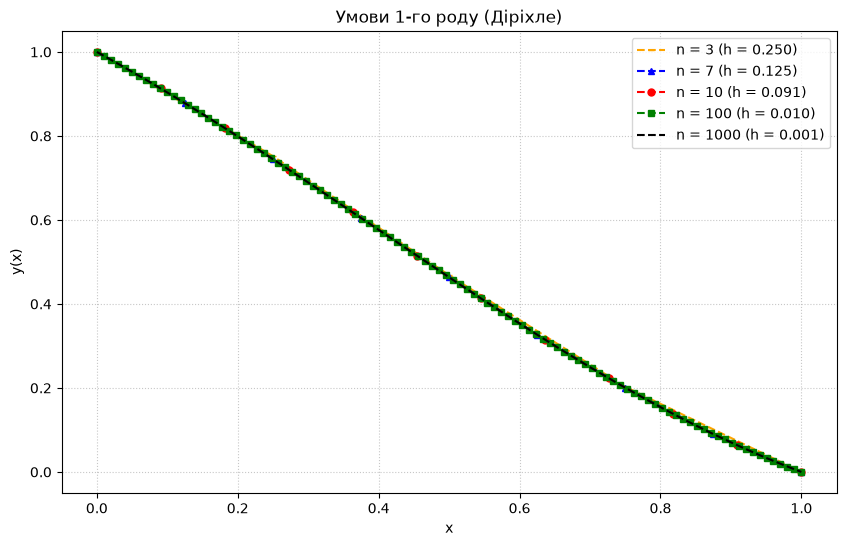

In [114]:
def modify_array_dirichle(A: np.ndarray, B: np.ndarray, C: np.ndarray, D: np.ndarray, A_0: float, C_np: float, y_start: float, y_end: float, h: float) -> None:
    D[0] -= A_0 * y_start
    D[-1] -= C_np * y_end

y = solve_task1(
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    y_start=1,
    y_end=0,
    limits=[0, 1],
    modify_array=modify_array_dirichle,
    modify_yse=lambda y1, y2, y_inside, h: (y1, y2),
    n=4
)

plot_comparisons(
    task_name="Умови 1-го роду (Діріхле)",
    modify_array_func=modify_array_dirichle,
    modify_yse_func=lambda y1, y2, y_in, h: (y1, y2),
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    limits=[0, 1],
    y_start=1,
    y_end=0
)

# Завдання 1.2. Граничні умови 2-го роду (Неймана) (4)
$$ y^{\prime\prime} + x^2 \cdot y^{\prime} + y = \sin{x}, x \in \left[ 0, 1 \right], y^{\prime}\left( 0 \right) = 1, y^{\prime}\left( 1 \right) = 0 $$

\begin{equation*}
y'(x_0) \approx \frac{y_1 - y_0}{h} = Y'_{\text{Left}}
\end{equation*}

\begin{equation*}
y_0 = y_1 - Y'_{\text{Left}} h
\end{equation*}

\begin{equation*}
A_1 (y_1 - Y'_{\text{Left}} h) + B_1 y_1 + C_1 y_2 = D_1
\end{equation*}

\begin{equation*}
A_1 y_1 - A_1 Y'_{\text{Left}} h + B_1 y_1 + C_1 y_2 = D_1
\end{equation*}

\begin{equation*}
y_1 (A_1 + B_1) + C_1 y_2 = D_1 + A_1 Y'_{\text{Left}} h
\end{equation*}

\begin{equation*}
\overline{B_1} y_1 + \overline{C_1} y_2 = \overline{D_1}
\end{equation*}

\begin{equation*}
\overline{B_1} = A_1 + B_1 \quad (B_1 \rightarrow B_1 + A_1)
\end{equation*}

\begin{equation*}
\overline{D_1} = D_1 + A_1 Y'_{\text{Left}} h \quad (D_1 \rightarrow D_1 + A_1 Y'_{\text{Left}} h)
\end{equation*}


\begin{equation*}
y'(x_{n+1}) = Y'_{\text{Right}}
\end{equation*}

\begin{equation*}
y'(x_{n+1}) \approx \frac{y_{n+1} - y_n}{h} = Y'_{\text{Right}}
\end{equation*}

\begin{equation*}
y_{n+1} = y_n + h Y'_{\text{Right}}
\end{equation*}

\begin{equation*}
A_n y_{n-1} + B_n y_n + C_n (y_n + h Y'_{\text{Right}}) = D_n
\end{equation*}

\begin{equation*}
A_n y_{n-1} + y_n (C_n + B_n) = D_n - C_n h Y'_{\text{Right}}
\end{equation*}

\begin{equation*}
\overline{A_n} y_{n-1} + \overline{B_n} y_n = \overline{D_n}
\end{equation*}

\begin{equation*}
\overline{B_n} = B_n + C_n \quad (B_n \rightarrow B_n + C_n)
\end{equation*}

\begin{equation*}
\overline{D_n} = D_n - C_n h Y'_{\text{Right}} \quad (D_n \rightarrow D_n - C_n h Y'_{\text{Right}})
\end{equation*}


\begin{equation*}
y_0^{\prime} = \frac{y_1 - y_0}{h}
\end{equation*}

\begin{equation*}
y_0^{\prime} \cdot h = y_1 - y_0
\end{equation*}

\begin{equation*}
\boxed{y_0 = y_1 - y_0^{\prime} \cdot h}
\end{equation*}


\begin{equation*}
y_{n}^{\prime} = \frac{y_{n+1} - y_n}{h}
\end{equation*}

\begin{equation*}
y_{n}^{\prime} \cdot h = y_{n+1} - y_n
\end{equation*}

\begin{equation*}
\boxed{y_{n+1} = y_n + y_n^{\prime} \cdot h}
\end{equation*}

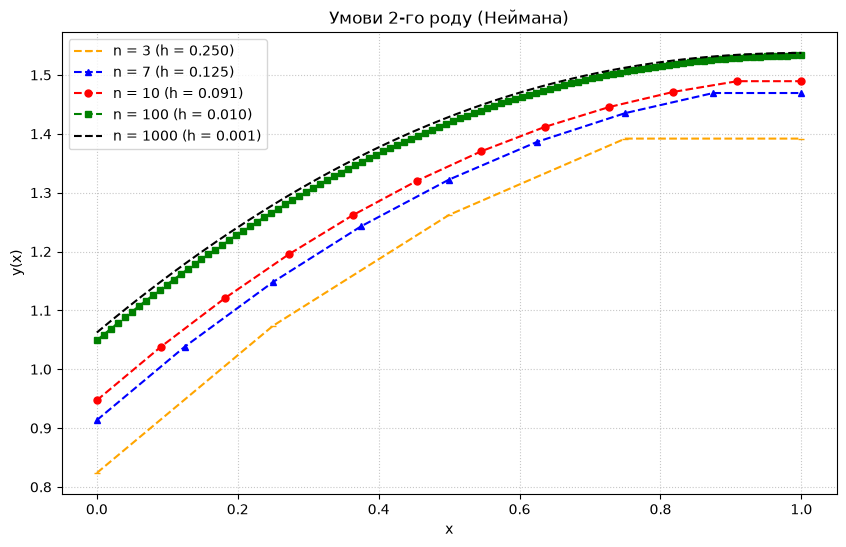

In [115]:
def modify_array_neiman(A: np.ndarray, B: np.ndarray, C: np.ndarray, D: np.ndarray, A_0: float, C_np: float, y_start: float, y_end: float, h: float) -> None:
    B[0] += A_0
    D[0] += A_0 * y_start * h
    B[-1] += C_np
    D[-1] -= C_np * h * y_end

def modify_yse_neiman(y_start: float, y_end: float, y_inside: np.ndarray, h: float) -> tuple[float, float]:
    y_start = y_inside[0] - h * y_start
    y_end = y_inside[-1] + h * y_end

    return y_start, y_end

solve_task1(
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    y_start=1,
    y_end=0,
    limits=[0, 1],
    modify_array=modify_array_neiman,
    modify_yse=modify_yse_neiman,
    n=4
)

plot_comparisons(
    task_name="Умови 2-го роду (Неймана)",
    modify_array_func=modify_array_neiman,
    modify_yse_func=modify_yse_neiman,
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    limits=[0, 1],
    y_start=1,
    y_end=0
)

# Завдання 1.3. Граничні умови 3-го роду (Робіна) (4)
$$ y^{\prime\prime} + x^2 \cdot y^{\prime} + y = \sin{x}, x \in \left[ 0, 1 \right], y\left( 0 \right) + y^{\prime}\left( 0 \right) = 1, 2 \cdot y\left( 1 \right) + y^{\prime}\left( 1 \right) = 0 $$


\begin{equation*}
\alpha_1 y(a) + \beta_1 y'(a) = Left_{\text{value}}, \quad \alpha_2 y(b) + \beta_2 y'(b) = Right_{\text{value}}
\end{equation*}

\begin{equation*}
\alpha_1 y(x_0) + \beta_1 y'(x_0) = Left_{\text{value}}
\end{equation*}

\begin{equation*}
\alpha_1 y_0 + \beta_1 \frac{y_1 - y_0}{h} = Left_{\text{value}}
\end{equation*}

\begin{equation*}
\alpha_1 y_0 h + \beta_1 (y_1 - y_0) = h \, Left_{\text{value}}
\end{equation*}

\begin{equation*}
y_0 (\alpha_1 h - \beta_1) + \beta_1 y_1 = h \, Left_{\text{value}}
\end{equation*}

\begin{equation*}
y_0 = \frac{\beta_1}{\beta_1 - \alpha_1 h} y_1 - \frac{h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h}
\end{equation*}

\begin{equation*}
A_1 y_0 + B_1 y_1 + C_1 y_2 = D_1
\end{equation*}

\begin{equation*}
A_1 \left( \frac{\beta_1}{\beta_1 - \alpha_1 h} y_1 - \frac{h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h} \right) + B_1 y_1 + C_1 y_2 = D_1
\end{equation*}

\begin{equation*}
y_1 \left( B_1 + A_1 \frac{\beta_1}{\beta_1 - \alpha_1 h} \right) + C_1 y_2 = D_1 + A_1 \frac{h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h}
\end{equation*}

\begin{equation*}
\overline{B_1} = B_1 + A_1 \frac{\beta_1}{\beta_1 - \alpha_1 h} \quad \left( B_1 \rightarrow B_1 + A_1 \frac{\beta_1}{\beta_1 - \alpha_1 h} \right)
\end{equation*}

\begin{equation*}
\overline{D_1} = D_1 + A_1 \frac{h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h} \quad \left( D_1 \rightarrow D_1 + A_1 \frac{h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h} \right)
\end{equation*}


\begin{equation*}
\alpha_2 y(x_{n+1}) + \beta_2 y'(x_{n+1}) = Right_{\text{value}}
\end{equation*}

\begin{equation*}
\alpha_2 y_{n+1} + \beta_2 \frac{y_{n+1} - y_n}{h} = Right_{\text{value}}
\end{equation*}

\begin{equation*}
\alpha_2 h y_{n+1} + \beta_2 (y_{n+1} - y_n) = h \, Right_{\text{value}}
\end{equation*}

\begin{equation*}
y_{n+1}(\alpha_2 h + \beta_2) - \beta_2 y_n = h \, Right_{\text{value}}
\end{equation*}

\begin{equation*}
y_{n+1} =
\frac{\beta_2}{\alpha_2 h + \beta_2} y_n +
\frac{h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}
\end{equation*}

\begin{equation*}
A_n y_{n-1} + B_n y_n + C_n y_{n+1} = D_n
\end{equation*}

\begin{equation*}
A_n y_{n-1} + B_n y_n +
C_n \left(
\frac{\beta_2}{\alpha_2 h + \beta_2} y_n +
\frac{h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}
\right) = D_n
\end{equation*}

\begin{equation*}
A_n y_{n-1} +
y_n \left(
B_n + C_n \frac{\beta_2}{\alpha_2 h + \beta_2}
\right) =
D_n - C_n \frac{h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}
\end{equation*}

\begin{equation*}
\overline{A_n} = A_n
\end{equation*}

\begin{equation*}
\overline{B_n} = B_n + C_n \frac{\beta_2}{\alpha_2 h + \beta_2}
\quad
\left(
B_n \rightarrow B_n + C_n \frac{\beta_2}{\alpha_2 h + \beta_2}
\right)
\end{equation*}

\begin{equation*}
\overline{D_n} = D_n - C_n \frac{h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}
\quad
\left(
D_n \rightarrow D_n - C_n \frac{h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}
\right)
\end{equation*}

\begin{equation*}
y_0^{\prime} = \frac{y_1 - y_0}{h}
\end{equation*}

\begin{equation*}
y_0^{\prime} \cdot h = y_1 - y_0
\end{equation*}

\begin{equation*}
y_0 = y_1 - y_0^{\prime} \cdot h
\end{equation*}

\begin{equation*}
\alpha_1 y_0 + \beta_1 y_0^{\prime} = Left_{\text{value}} \quad \Rightarrow \quad y_0^{\prime} = \frac{Left_{\text{value}} - \alpha_1 y_0}{\beta_1}
\end{equation*}

\begin{equation*}
y_0 = y_1 - h \, \frac{Left_{\text{value}} - \alpha_1 y_0}{\beta_1}
\end{equation*}

\begin{equation*}
\beta_1 y_0 = \beta_1 y_1 - h \, Left_{\text{value}} + \alpha_1 h \, y_0
\end{equation*}

\begin{equation*}
y_0 \left( \beta_1 - \alpha_1 h \right) = \beta_1 y_1 - h \, Left_{\text{value}}
\end{equation*}

\begin{equation*}
\boxed{y_0 = \frac{\beta_1 y_1 - h \, Left_{\text{value}}}{\beta_1 - \alpha_1 h}}
\end{equation*}

\begin{equation*}
y_{n+1}^{\prime} = \frac{y_{n+1} - y_n}{h}
\end{equation*}

\begin{equation*}
y_{n+1}^{\prime} \cdot h = y_{n+1} - y_n
\end{equation*}

\begin{equation*}
y_{n+1} = y_n + y_{n+1}^{\prime} \cdot h
\end{equation*}

\begin{equation*}
\alpha_2 y_{n+1} + \beta_2 y_{n+1}^{\prime} = Right_{\text{value}} \quad \Rightarrow \quad y_{n+1}^{\prime} = \frac{Right_{\text{value}} - \alpha_2 y_{n+1}}{\beta_2}
\end{equation*}

\begin{equation*}
y_{n+1} = y_n + h \, \frac{Right_{\text{value}} - \alpha_2 y_{n+1}}{\beta_2}
\end{equation*}

\begin{equation*}
\beta_2 y_{n+1} = \beta_2 y_n + h \, Right_{\text{value}} - \alpha_2 h \, y_{n+1}
\end{equation*}

\begin{equation*}
y_{n+1} \left( \beta_2 + \alpha_2 h \right) = \beta_2 y_n + h \, Right_{\text{value}}
\end{equation*}

\begin{equation*}
\boxed{y_{n+1} = \frac{\beta_2 y_n + h \, Right_{\text{value}}}{\alpha_2 h + \beta_2}}
\end{equation*}

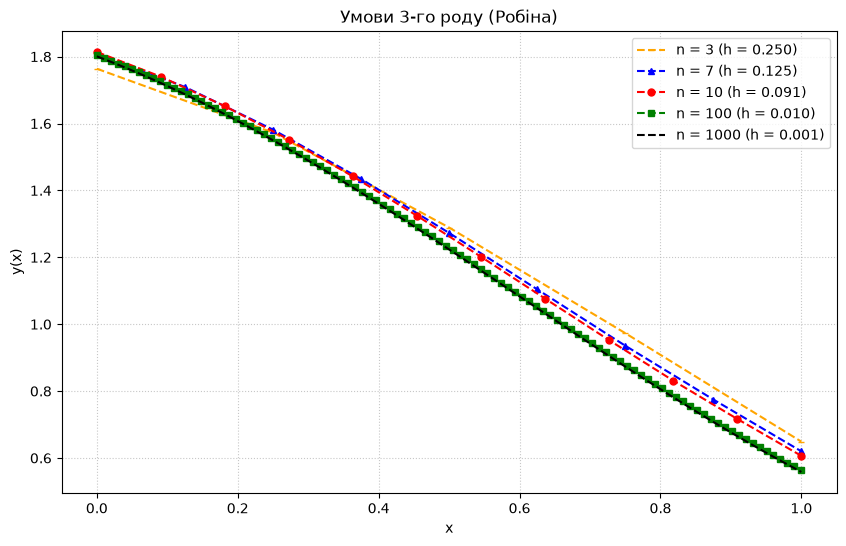

In [116]:
alpha = [1, 2]
beta = [1, 1]

def modify_array_robin(A: np.ndarray, B: np.ndarray, C: np.ndarray, D: np.ndarray, A_0: float, C_np: float, y_start: float, y_end: float, h: float) -> None:
    B[0] += A_0 * beta[0]/(beta[0] - alpha[0] * h)
    D[0] += A_0 * (y_start * h)/(beta[0] - alpha[0] * h)
    B[-1] += C_np * beta[1]/(alpha[1] * h + beta[1])
    D[-1] -= C_np * (h * y_end)/(alpha[1] * h + beta[1])

def modify_yse_robin(y_start: float, y_end: float, y_inside: np.ndarray, h: float) -> tuple[float, float]:
    y_start = (beta[0] * y_inside[0]  - h * y_start)  / (beta[0] - alpha[0] * h)
    y_end = (beta[1] * y_inside[-1] + h * y_end) / (alpha[1] * h + beta[1])

    return y_start, y_end

solve_task1(
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    y_start=1,
    y_end=0,
    limits=[0, 1],
    modify_array=modify_array_robin,
    modify_yse=modify_yse_robin,
    n=4
)


plot_comparisons(
    task_name="Умови 3-го роду (Робіна)",
    modify_array_func=modify_array_robin,
    modify_yse_func=modify_yse_robin,
    P=lambda x: 1 + 0*x,
    Q=lambda x: x**2,
    R=lambda x: 1 + 0*x,
    f=lambda x: np.sin(x),
    limits=[0, 1],
    y_start=1,
    y_end=0
)

# Завдання 2. Граничні задачі для диференціальних рівнянь другого порядку у частинних похідних в декартовій системі координат (4)
$$
\frac{\partial}{\partial{x}} \left( \frac{k_{x}\left( x, y \right) \partial{u}}{\partial{x}} \right)
+ \frac{\partial}{\partial{y}} \left( \frac{k_{y}\left( x, y \right) \partial{u}}{\partial{x}} \right)
- q\left( x, y \right) \cdot u
= f\left( x, y \right)
$$
$$ \left( x, y \right) \in \left[ A; B \right] \times \left[ C; D \right] $$

$$ \left[ A; B \right] \times \left[ C; D \right] = \left[ 0.8, 2.5 \right] \times \left[ 1, 2 \right] $$
$$ k_{x} = 1 + x^{2} + 0.2 \cdot y^2, k_{y} = 1 + 0.5 \cdot x \cdot y, q = - \left( x + y \right), f = \cos{ \left( x \cdot y \right)} $$
$$ \frac{\partial{u}}{\partial{y}} \left( 0.8, y \right) = 0, u \left( 2.5, y \right) = \sin{y} $$

\begin{equation*}
\frac{\partial u}{\partial x}(0.8, y) = 0
\end{equation*}

\begin{equation*}
\frac{u_{1, j} - u_{0, j}}{h_x} = 0
\end{equation*}

\begin{equation*}
u_{0, j} = u_{1, j}
\end{equation*}

\begin{equation*}
u(2.5, y) = \sin{y}
\end{equation*}

\begin{equation*}
u_{n_x, j} = \sin{y_j}
\end{equation*}

In [117]:
def seidel_solver(
    u: np.ndarray,
    update_inner: Callable[[np.ndarray], np.ndarray],
    update_boundary: Callable[[np.ndarray], np.ndarray],
    tol: float = 1e-5,
    max_iter: int = 5000
) -> np.ndarray:
    
    for _ in range(max_iter):
        u_old = u.copy()
        
        u = update_inner(u)
        u = update_boundary(u)
        
        if np.max(np.abs(u - u_old)) < tol:
            break
            
    return u

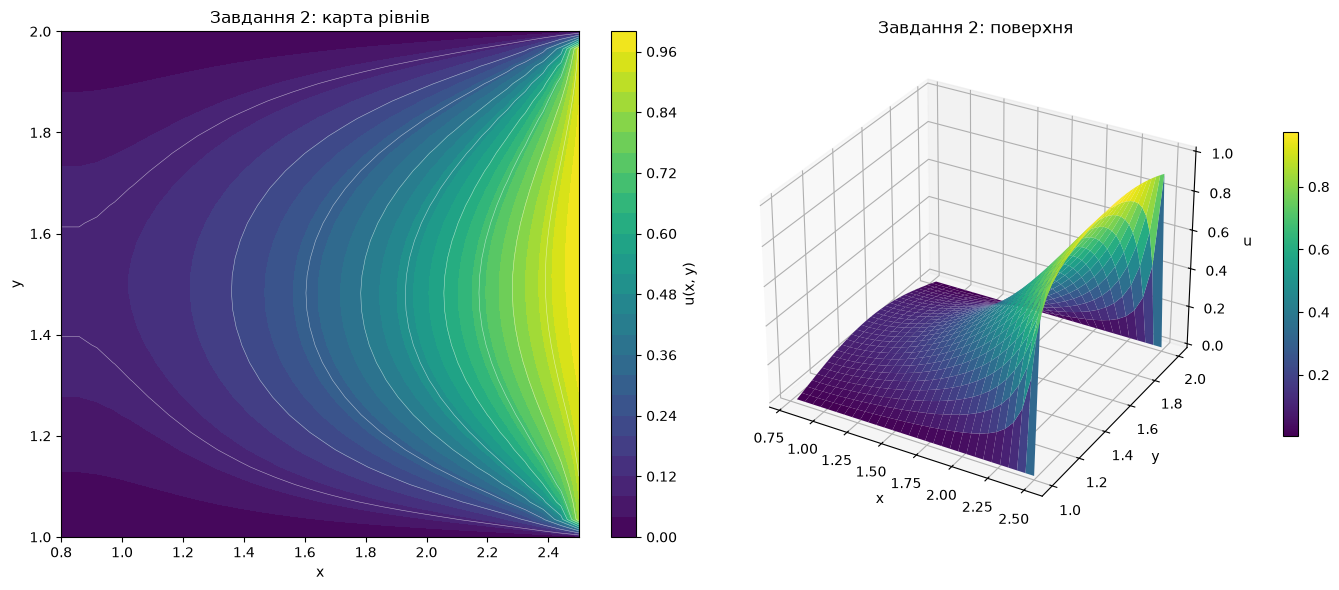

In [118]:
def solve_task2(nx=30, ny=30):
    x = np.linspace(0.8, 2.5, nx)
    y = np.linspace(1.0, 2.0, ny)
    hx, hy = x[1] - x[0], y[1] - y[0]
    u = np.zeros((nx, ny))
    
    kx = lambda x, y: 1 + x**2 + 0.2 * y**2
    ky = lambda x, y: 1 + 0.5 * x * y
    q = lambda x, y: -(x + y)
    f = lambda x, y: np.cos(x * y)

    def update_inner(u_curr):
        for i in range(1, nx - 1):
            for j in range(1, ny - 1):
                A = kx(x[i] + hx/2, y[j]) / hx**2
                B = kx(x[i] - hx/2, y[j]) / hx**2
                C = ky(x[i], y[j] + hy/2) / hy**2
                D = ky(x[i], y[j] - hy/2) / hy**2
                E = A + B + C + D + q(x[i], y[j])
                
                u_curr[i, j] = (A * u_curr[i+1, j] + B * u_curr[i-1, j] + C * u_curr[i, j+1] + D * u_curr[i, j-1] - f(x[i], y[j])) / E
        return u_curr

    def update_boundary(u_curr):
        u_curr[0, :] = u_curr[1, :]
        u_curr[-1, :] = np.sin(y)
        u_curr[:, 0] = 0.0
        u_curr[:, -1] = 0.0
        return u_curr

    return seidel_solver(u, update_inner, update_boundary)

nx, ny = 30, 30
u = solve_task2(nx, ny)
x = np.linspace(0.8, 2.5, nx)
y = np.linspace(1.0, 2.0, ny)
X, Y = np.meshgrid(x, y, indexing='ij')

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(X, Y, u, levels=30, cmap='viridis')
ax1.contour(X, Y, u, levels=10, colors='white', linewidths=0.4, alpha=0.6)
fig.colorbar(cf, ax=ax1, label='u(x, y)')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Завдання 2: карта рівнів')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf = ax2.plot_surface(X, Y, u, cmap='viridis', edgecolor='none')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('u')
ax2.set_title('Завдання 2: поверхня')
fig.colorbar(surf, ax=ax2, shrink=0.6, pad=0.1)

plt.tight_layout()
plt.show()


# Завдання 3. Рівняння Пуассона, яке задане у полярній системі координат (4)
$$
\Delta{u \left( r, \varphi \right)}
= \frac{1}{r} \cdot \frac{\partial}{\partial{r}} \left( r \cdot \frac{\partial{u}}{\partial{r}} \right)
+ \frac{1}{r^2} \cdot \frac{\partial^2{u}}{\partial{\varphi^2}}
= f \left( r, \varphi \right)
$$

$$
r \in \left[ 0.7; 2.0 \right],
\varphi \in \left[ 0, \frac{\pi}{4} \right],
f \left( r, \varphi \right) = r \cdot \sin{\varphi}
$$

$$
u \left( 0.7, \varphi \right) = 0,
\frac{\partial{u}}{\partial{r}}\left( 2.0, \varphi \right) = \varphi^2
$$
$$
2 \cdot u + 3 \cdot \frac{\partial{u}}{\partial{\varphi}}\left( r, 0 \right) = 1, 
u - 2 \cdot \frac{\partial{u}}{\partial{\varphi}}\left( r, \frac{\pi}{4} \right) = 0 

$$


\begin{equation*}
u(0.7, \varphi) = 0
\end{equation*}

\begin{equation*}
u_{0, j} = 0
\end{equation*}

\begin{equation*}
\frac{\partial u}{\partial r}(2.0, \varphi) = \varphi^2
\end{equation*}

\begin{equation*}
\frac{u_{n_r, j} - u_{n_r-1, j}}{h_r} = \varphi_j^2
\end{equation*}

\begin{equation*}
u_{n_r, j} = u_{n_r-1, j} + h_r \varphi_j^2
\end{equation*}

\begin{equation*}
2 u(r, 0) + 3 \frac{\partial u}{\partial \varphi}(r, 0) = 1
\end{equation*}

\begin{equation*}
2 u_{i, 0} + 3 \frac{u_{i, 1} - u_{i, 0}}{h_\varphi} = 1
\end{equation*}

\begin{equation*}
2 h_\varphi u_{i, 0} + 3 u_{i, 1} - 3 u_{i, 0} = h_\varphi
\end{equation*}

\begin{equation*}
u_{i, 0} \left( 2 h_\varphi - 3 \right) = h_\varphi - 3 u_{i, 1}
\end{equation*}

\begin{equation*}
u_{i, 0} = \frac{3 u_{i, 1} - h_\varphi}{3 - 2 h_\varphi}
\end{equation*}

\begin{equation*}
u(r, \frac{\pi}{4}) - 2 \frac{\partial u}{\partial \varphi}(r, \frac{\pi}{4}) = 0
\end{equation*}

\begin{equation*}
u_{i, n_\varphi} - 2 \frac{u_{i, n_\varphi} - u_{i, n_\varphi-1}}{h_\varphi} = 0
\end{equation*}

\begin{equation*}
h_\varphi u_{i, n_\varphi} - 2 u_{i, n_\varphi} + 2 u_{i, n_\varphi-1} = 0
\end{equation*}

\begin{equation*}
u_{i, n_\varphi} \left( h_\varphi - 2 \right) = - 2 u_{i, n_\varphi-1}
\end{equation*}

\begin{equation*}
u_{i, n_\varphi} = \frac{2 u_{i, n_\varphi-1}}{2 - h_\varphi}
\end{equation*}

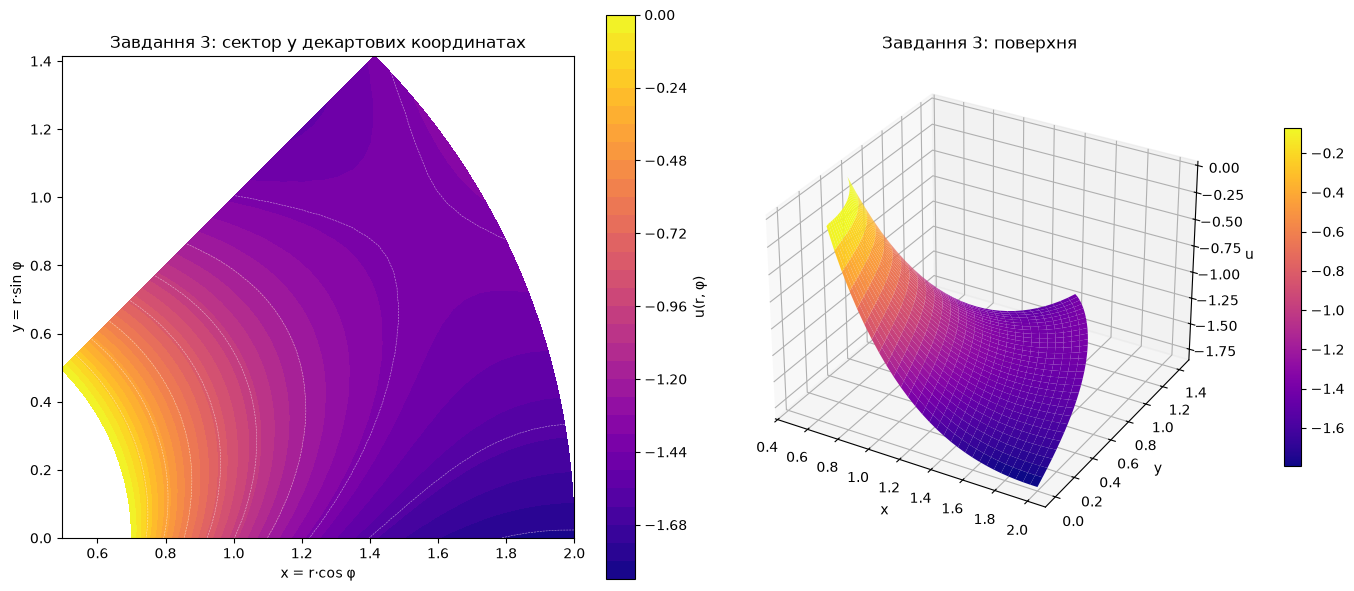

In [119]:
def solve_task3(nr=30, nphi=30):
    r = np.linspace(0.7, 2.0, nr)
    phi = np.linspace(0, np.pi/4, nphi)
    hr, hphi = r[1] - r[0], phi[1] - phi[0]
    u = np.zeros((nr, nphi))
    
    def update_inner(u_curr):
        for i in range(1, nr - 1):
            for j in range(1, nphi - 1):
                f_val = r[i] * np.sin(phi[j])
                C_val = 2/hr**2 + 2/(r[i]**2 * hphi**2)
                
                term_r = ((r[i] + hr/2)*u_curr[i+1, j] + (r[i] - hr/2)*u_curr[i-1, j]) / (r[i] * hr**2)
                term_phi = (u_curr[i, j+1] + u_curr[i, j-1]) / (r[i]**2 * hphi**2)
                
                u_curr[i, j] = (term_r + term_phi - f_val) / C_val
        return u_curr

    def update_boundary(u_curr):
        u_curr[0, :] = 0.0
        u_curr[-1, :] = u_curr[-2, :] + hr * phi**2
        u_curr[:, 0] = (3 * u_curr[:, 1] - hphi) / (3 - 2 * hphi)
        u_curr[:, -1] = 2 * u_curr[:, -2] / (2 - hphi)
        return u_curr

    return seidel_solver(u, update_inner, update_boundary)

nr, nphi = 30, 30
u = solve_task3(nr, nphi)
r = np.linspace(0.7, 2.0, nr)
phi = np.linspace(0, np.pi / 4, nphi)
R, PHI = np.meshgrid(r, phi, indexing='ij')
Xc, Yc = R * np.cos(PHI), R * np.sin(PHI)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(Xc, Yc, u, levels=30, cmap='plasma')
ax1.contour(Xc, Yc, u, levels=10, colors='white', linewidths=0.4, alpha=0.6)
fig.colorbar(cf, ax=ax1, label='u(r, φ)')
ax1.set_aspect('equal')
ax1.set_xlabel('x = r·cos φ')
ax1.set_ylabel('y = r·sin φ')
ax1.set_title('Завдання 3: сектор у декартових координатах')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf = ax2.plot_surface(Xc, Yc, u, cmap='plasma', edgecolor='none')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('u')
ax2.set_title('Завдання 3: поверхня')
fig.colorbar(surf, ax=ax2, shrink=0.6, pad=0.1)

plt.tight_layout()
plt.show()


# Завдання 4. Рівняння Пуассона, яке задане у полярній системі координат (осесиметричний випадок) (4)
$$
\Delta u(r)
= \frac{1}{r} \frac{d}{dr} \left( r \frac{\partial u}{\partial r} \right)
= f(r)
$$

$$
\begin{gathered}
r \in [1, 3], \quad f(r) = r \\
u(1) + \frac{du}{dr}(1) = 0, \quad u(3) = \cos 3
\end{gathered}
$$


$$\frac{1}{r} \frac{d}{dr} \left( r \frac{du}{dr} \right) = r \quad$$
$$\quad \frac{1}{r} \left( 1 \cdot u' + r \cdot u'' \right) = r \quad$$
$$\quad u'' + \frac{1}{r} u' = r$$

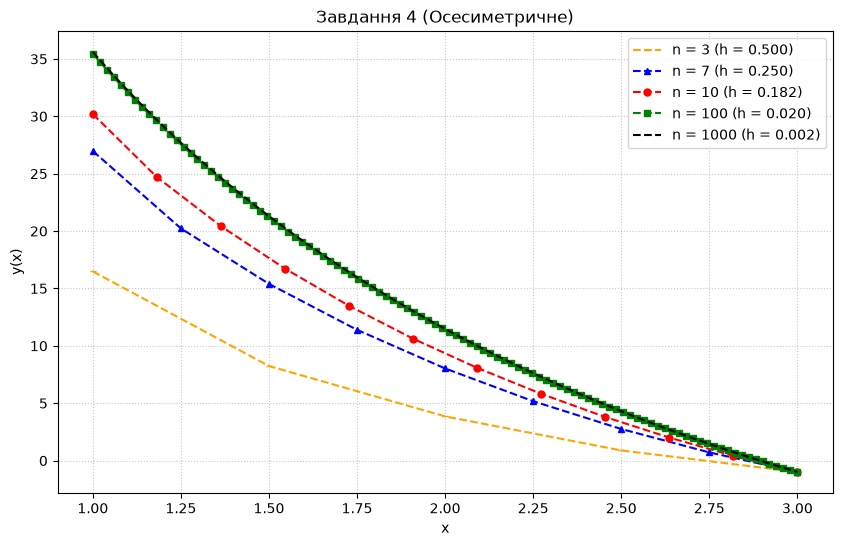

In [120]:
alpha_1, beta_1 = 1, 1

def modify_array_task4(A: np.ndarray, B: np.ndarray, C: np.ndarray, D: np.ndarray, A_0: float, C_np: float, u_start: float, u_end: float, h: float) -> None:
    B[0] += A_0 * beta_1 / (beta_1 - alpha_1 * h)
    D[0] += A_0 * (u_start * h) / (beta_1 - alpha_1 * h)
    D[-1] -= C_np * u_end

def modify_yse_task4(u_start: float, u_end: float, u_inside: np.ndarray, h: float) -> tuple[float, float]:
    u_start = (beta_1 * u_inside[0] - h * u_start) / (beta_1 - alpha_1 * h)
    return u_start, u_end

u_task4 = solve_task1(
    P=lambda r: 1 + 0*r,
    Q=lambda r: 1/r,
    R=lambda r: 0*r,
    f=lambda r: r,
    y_start=0,
    y_end=np.cos(3),
    limits=[1, 3],
    modify_array=modify_array_task4,
    modify_yse=modify_yse_task4,
    n=50
)

plot_comparisons(
    task_name="Завдання 4 (Осесиметричне)",
    modify_array_func=modify_array_task4,
    modify_yse_func=modify_yse_task4,
    P=lambda r: 1 + 0*r,
    Q=lambda r: 1/r,
    R=lambda r: 0*r,
    f=lambda r: r,
    limits=[1, 3],
    y_start=0,
    y_end=np.cos(3)
)

# Завдання 5. Рівняння Пуассона у декартових тривимірних координатах (4)
$$
\frac{\partial^2 u}{\partial x^2}
+ \frac{\partial^2 u}{\partial y^2}
+ \frac{\partial^2 u}{\partial z^2}
= f(x, y, z)
$$

$$
\begin{gathered}
x \in [0; 2], \, y \in [0, 2], \, z \in [0, 1], \\
f(x, y, z) = e^{-x-y-z} \\
u(0, y, z) + \frac{\partial u}{\partial x}(0, y, z) = 1, \quad u(2, y, z) = 1 \\
\frac{\partial u}{\partial y}(x, 0, z) = 0, \quad u(x, 2, z) - 2\frac{\partial u}{\partial y}(x, 2, z) = 1 \\
u(x, y, 0) = 0, \quad \frac{\partial u}{\partial z}(x, y, 1) = 2
\end{gathered}
$$

\begin{equation*}
u(0, y, z) + \frac{\partial u}{\partial x}(0, y, z) = 1
\end{equation*}

\begin{equation*}
u_{0, j, k} + \frac{u_{1, j, k} - u_{0, j, k}}{h_x} = 1
\end{equation*}

\begin{equation*}
h_x u_{0, j, k} + u_{1, j, k} - u_{0, j, k} = h_x
\end{equation*}

\begin{equation*}
u_{0, j, k} \left( h_x - 1 \right) = h_x - u_{1, j, k}
\end{equation*}

\begin{equation*}
u_{0, j, k} = \frac{u_{1, j, k} - h_x}{1 - h_x}
\end{equation*}

\begin{equation*}
u(2, y, z) = 1
\end{equation*}

\begin{equation*}
u_{n_x, j, k} = 1
\end{equation*}

\begin{equation*}
\frac{\partial u}{\partial y}(x, 0, z) = 0
\end{equation*}

\begin{equation*}
\frac{u_{i, 1, k} - u_{i, 0, k}}{h_y} = 0
\end{equation*}

\begin{equation*}
u_{i, 0, k} = u_{i, 1, k}
\end{equation*}

\begin{equation*}
u(x, 2, z) - 2 \frac{\partial u}{\partial y}(x, 2, z) = 1
\end{equation*}

\begin{equation*}
u_{i, n_y, k} - 2 \frac{u_{i, n_y, k} - u_{i, n_y-1, k}}{h_y} = 1
\end{equation*}

\begin{equation*}
h_y u_{i, n_y, k} - 2 u_{i, n_y, k} + 2 u_{i, n_y-1, k} = h_y
\end{equation*}

\begin{equation*}
u_{i, n_y, k} \left( h_y - 2 \right) = h_y - 2 u_{i, n_y-1, k}
\end{equation*}

\begin{equation*}
u_{i, n_y, k} = \frac{2 u_{i, n_y-1, k} - h_y}{2 - h_y}
\end{equation*}

\begin{equation*}
u(x, y, 0) = 0
\end{equation*}

\begin{equation*}
u_{i, j, 0} = 0
\end{equation*}

\begin{equation*}
\frac{\partial u}{\partial z}(x, y, 1) = 2
\end{equation*}

\begin{equation*}
\frac{u_{i, j, n_z} - u_{i, j, n_z-1}}{h_z} = 2
\end{equation*}

\begin{equation*}
u_{i, j, n_z} = u_{i, j, n_z-1} + 2 h_z
\end{equation*}

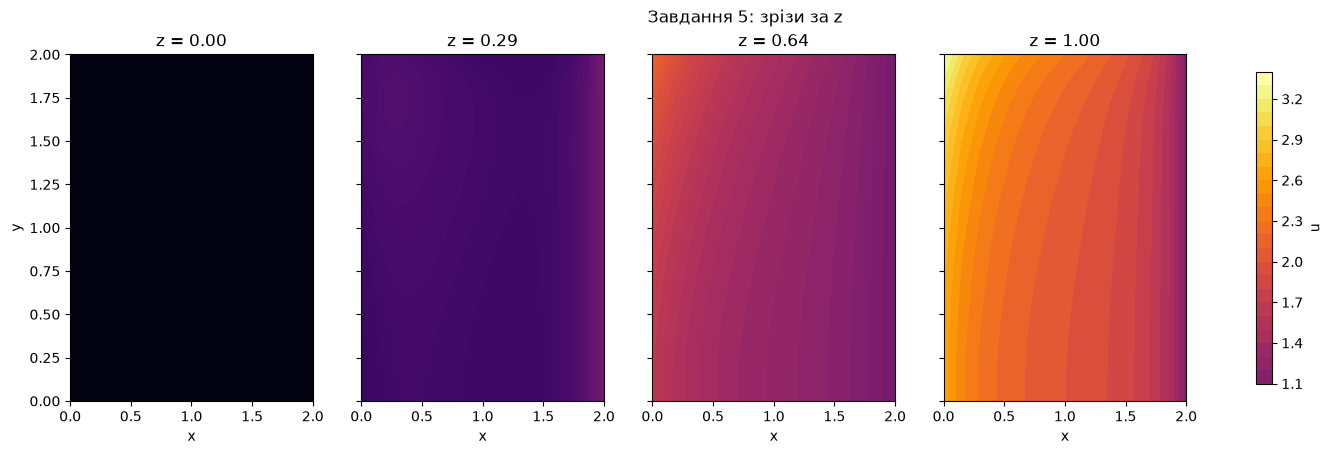

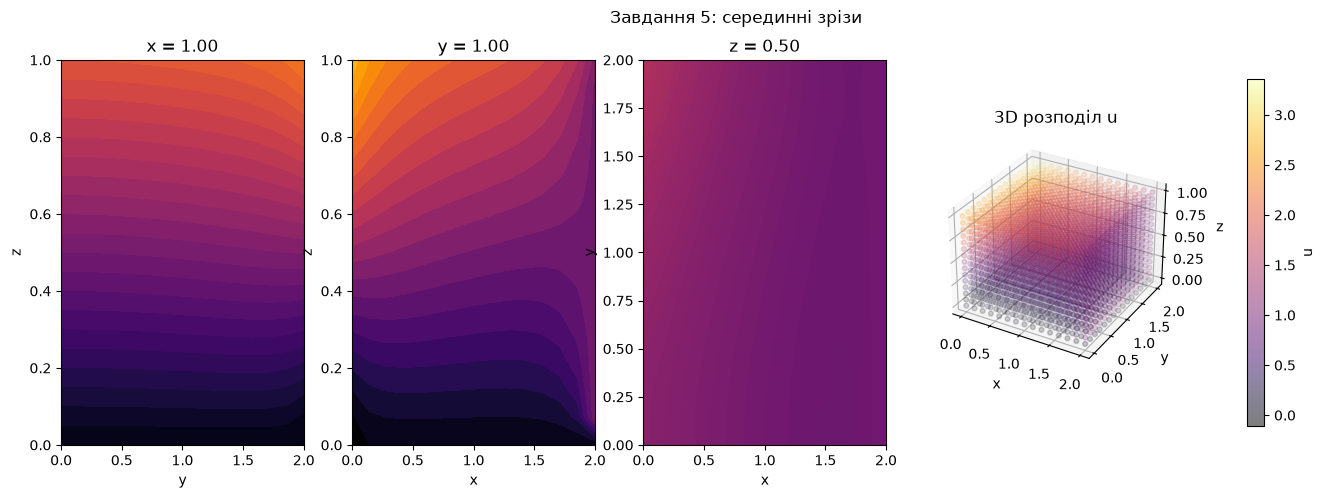

In [121]:
def solve_task5(nx=15, ny=15, nz=15):
    x = np.linspace(0, 2, nx)
    y = np.linspace(0, 2, ny)
    z = np.linspace(0, 1, nz)
    hx, hy, hz = x[1]-x[0], y[1]-y[0], z[1]-z[0]
    u = np.zeros((nx, ny, nz))
    
    C_val = 2/hx**2 + 2/hy**2 + 2/hz**2
    
    def update_inner(u_curr):
        for i in range(1, nx - 1):
            for j in range(1, ny - 1):
                for k in range(1, nz - 1):
                    f_val = np.exp(-x[i] - y[j] - z[k])
                    term = (u_curr[i+1,j,k] + u_curr[i-1,j,k])/hx**2 + \
                           (u_curr[i,j+1,k] + u_curr[i,j-1,k])/hy**2 + \
                           (u_curr[i,j,k+1] + u_curr[i,j,k-1])/hz**2
                    u_curr[i,j,k] = (term - f_val) / C_val
        return u_curr

    def update_boundary(u_curr):
        u_curr[0,:,:] = (u_curr[1,:,:] - hx) / (1 - hx)
        u_curr[-1,:,:] = 1.0
        u_curr[:,0,:] = u_curr[:,1,:]
        u_curr[:,-1,:] = (2*u_curr[:,-2,:] - hy) / (2 - hy)
        u_curr[:,:,0] = 0.0
        u_curr[:,:,-1] = u_curr[:,:,-2] + 2*hz
        return u_curr

    return seidel_solver(u, update_inner, update_boundary)

nx, ny, nz = 15, 15, 15
n_slices = 4

u = solve_task5(nx, ny, nz)
x = np.linspace(0, 2, nx)
y = np.linspace(0, 2, ny)
z = np.linspace(0, 1, nz)
vmin, vmax = u.min(), u.max()

ks = np.linspace(0, nz - 1, n_slices).astype(int)
fig, axes = plt.subplots(1, n_slices, figsize=(4.5 * n_slices, 4.5), sharey=True)
X, Y = np.meshgrid(x, y, indexing='ij')
for ax, k in zip(axes, ks):
    cf = ax.contourf(X, Y, u[:, :, k], levels=25, cmap='inferno', vmin=vmin, vmax=vmax)
    ax.set_title(f'z = {z[k]:.2f}')
    ax.set_xlabel('x')
axes[0].set_ylabel('y')
fig.colorbar(cf, ax=axes, label='u', shrink=0.9)
fig.suptitle('Завдання 5: зрізи за z')
plt.show()

i, j, k = nx // 2, ny // 2, nz // 2
fig = plt.figure(figsize=(18, 5))

ax = fig.add_subplot(1, 4, 1)
cf = ax.contourf(*np.meshgrid(y, z, indexing='ij'), u[i, :, :], levels=25,
                    cmap='inferno', vmin=vmin, vmax=vmax)
ax.set_title(f'x = {x[i]:.2f}')
ax.set_xlabel('y')
ax.set_ylabel('z')

ax = fig.add_subplot(1, 4, 2)
ax.contourf(*np.meshgrid(x, z, indexing='ij'), u[:, j, :], levels=25,
            cmap='inferno', vmin=vmin, vmax=vmax)
ax.set_title(f'y = {y[j]:.2f}')
ax.set_xlabel('x')
ax.set_ylabel('z')

ax = fig.add_subplot(1, 4, 3)
ax.contourf(X, Y, u[:, :, k], levels=25, cmap='inferno', vmin=vmin, vmax=vmax)
ax.set_title(f'z = {z[k]:.2f}')
ax.set_xlabel('x')
ax.set_ylabel('y')

ax = fig.add_subplot(1, 4, 4, projection='3d')
XX, YY, ZZ = np.meshgrid(x, y, z, indexing='ij')
sc = ax.scatter(XX.ravel(), YY.ravel(), ZZ.ravel(), c=u.ravel(),
                cmap='inferno', s=12, alpha=0.5, vmin=vmin, vmax=vmax)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('3D розподіл u')

fig.colorbar(sc, ax=fig.axes, label='u', shrink=0.9)
fig.suptitle('Завдання 5: серединні зрізи')
plt.show()
